In [1]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
from scipy.optimize import curve_fit
from glob import glob
import cmastro
import os
import matplotlib.pyplot as plt
import numpy as np
import pprint

plt.rcParams['image.origin'] = 'lower'

Useful functions for working with .fits files

In [2]:
def read_file(filename):
    image = fits.open("{f}".format(f=filename))[0].data.astype(int)
    return image

def header(filename):
    header = fits.open("{f}".format(f=filename))[0].header
    return header

def view(image, title):
    fig = plt.figure(figsize=(12, 6))
    vmin, vmax = ZScaleInterval().get_limits(image)
    plt.imshow(image, vmin=vmin, vmax=vmax, origin='lower', cmap='cma:lacerta')
    plt.title(title)
    plt.colorbar()
    plt.show()

def get_and_sort_files(folder, extension = 'fts'):
    # Get all .fts files
    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    # Pick out types of images and sort
    asteroid_files = [f for f in files if "26Proserpina-" in f]
    ast_headers = [header(f) for f in asteroid_files]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]
    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    return asteroid_files, ast_headers, flat_files, dark_files, bias_files   

**1. Get images categorized by date and type**

In [3]:
# 4 obs nights, 3 astroid images each
folder = "26Proserpina/"
observations = ["20120119", "20120120", "20120122", "20120125"]

# Images paths for each obs night
asteroid1, headers1, flats1, darks1, biases1 = get_and_sort_files(folder + observations[0])
asteroid2, headers2, flats2, darks2, biases2 = get_and_sort_files(folder + observations[1])
asteroid3, headers3, flats3, darks3, biases3 = get_and_sort_files(folder + observations[2])
asteroid4, headers4, flats4, darks4, biases4 = get_and_sort_files(folder + observations[3])


**2. Clean the images**

View all exposures and temperatures

In [4]:
flats = flats1 + flats2 + flats3 + flats4
darks = darks1 + darks2 + darks3 + darks4
biases = biases1 + biases2 + biases3 + biases4
astroids = asteroid1 + asteroid2 + asteroid3 + asteroid4
headers = headers1 + headers2 + headers3 + headers4
for asteroid in astroids:
    exp = header(asteroid)["EXPOSURE"]
    date = header(asteroid)["DATE-OBS"]
    temp = header(asteroid)["CCD-TEMP"]
    print("ASTEROID {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for flat in flats:
    exp = header(flat)["EXPOSURE"]
    date = header(flat)["DATE-OBS"]
    temp = header(flat)["CCD-TEMP"]
    print("FLAT {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for dark in darks:
    exp = header(dark)["EXPOSURE"]
    date = header(dark)["DATE-OBS"]
    temp = header(dark)["CCD-TEMP"]
    print("DARK {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for bias in biases:
    exp = header(bias)["EXPOSURE"]
    date = header(bias)["DATE-OBS"]
    temp = header(bias)["CCD-TEMP"]
    print("BIAS {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))

ASTEROID 2012-01-20T07:27:54 - Exposure: 60.0s, Temp: -25.218294750000005
ASTEROID 2012-01-20T07:29:21 - Exposure: 60.0s, Temp: -25.108281000000005
ASTEROID 2012-01-20T07:30:48 - Exposure: 60.0s, Temp: -25.117710750000004
ASTEROID 2012-01-21T07:39:37 - Exposure: 60.0s, Temp: -25.114567500000007
ASTEROID 2012-01-21T07:41:03 - Exposure: 60.0s, Temp: -25.023413250000004
ASTEROID 2012-01-21T07:42:29 - Exposure: 60.0s, Temp: -25.06113225
ASTEROID 2012-01-23T08:35:52 - Exposure: 60.0s, Temp: -25.183719
ASTEROID 2012-01-23T08:37:18 - Exposure: 60.0s, Temp: -25.14914325
ASTEROID 2012-01-23T08:38:44 - Exposure: 60.0s, Temp: -25.139713500000006
-----------------------------
FLAT 2012-01-20T00:44:14 - Exposure: 1.75s, Temp: -4.702302
FLAT 2012-01-20T00:44:28 - Exposure: 2.07s, Temp: -4.3691175
FLAT 2012-01-20T00:44:42 - Exposure: 2.21s, Temp: -3.9573517500000004
FLAT 2012-01-20T00:44:56 - Exposure: 2.35s, Temp: -3.62416725
FLAT 2012-01-20T00:45:10 - Exposure: 2.5s, Temp: -3.2092582500000004
FLAT 

For the first, night the temperature controller was apparently off when taking the darks, so master dark will be from only 2/3 nights.

In [5]:
flats = [flat for flat in flats if header(flat)["CCD-Temp"] < -15]

We only want 60s darks to match our sky images. Now to create median images to use for cleaning

In [6]:
darks60 = [dark for dark in darks if np.abs(header(dark)["EXPOSURE"] - 60) <= 1]
print(darks60)

['26Proserpina/20120119/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120125/Calibration/Dark

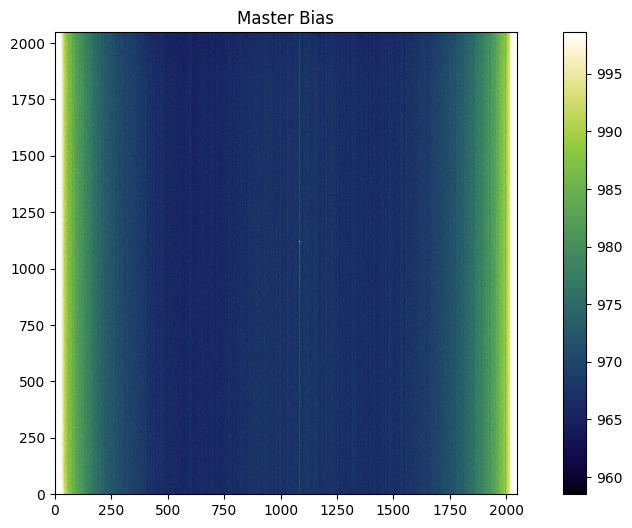

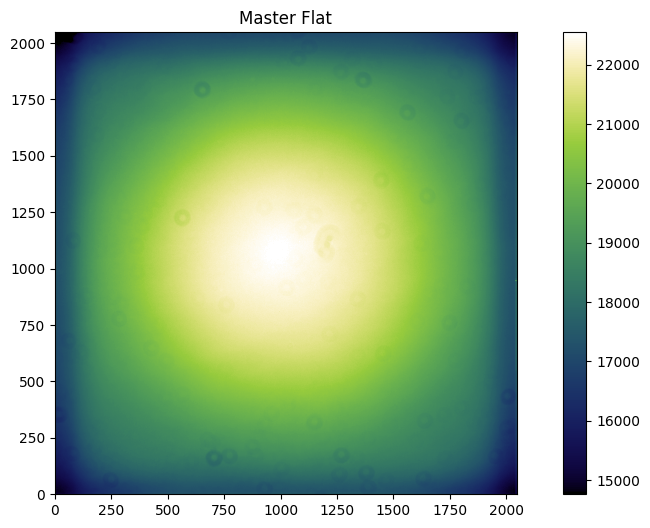

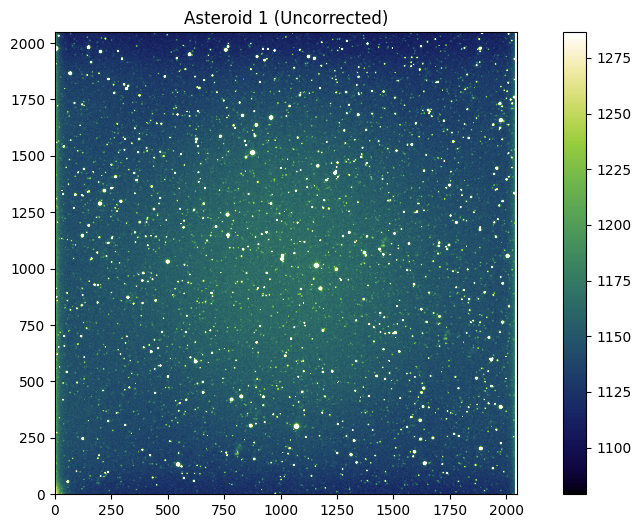

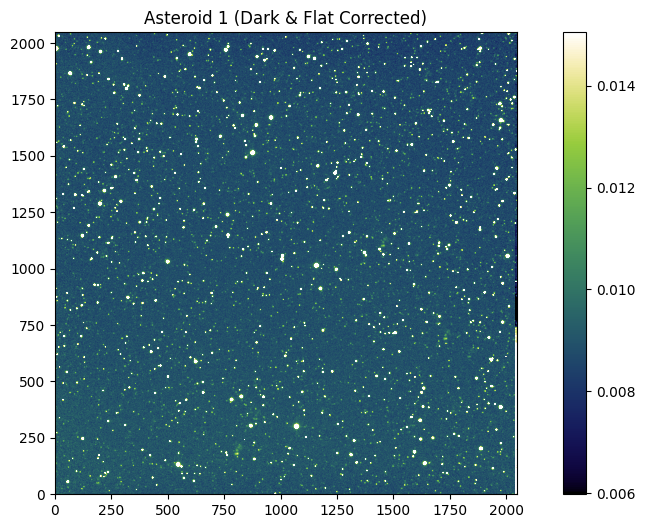

In [7]:
# Numpy arrays of images
all_astroid_np = np.array([read_file(f) for f in astroids])
all_biases_np = np.array([read_file(f) for f in biases])
all_dark60_np = np.array([read_file(f) for f in darks60])
all_flat_np = np.array([read_file(f) for f in flats])

# Flip science images
all_astroid_np = [all_astroid_np[::-1,::-1] for all_astroid_np in all_astroid_np]

# Median combine darks
master_dark = np.median(all_dark60_np, axis=0)
master_flat = np.median(all_flat_np, axis=0)
master_bias = np.median(all_biases_np, axis=0)

view(master_bias, "Master Bias")
view(master_flat, "Master Flat")

science_imgs = ((all_astroid_np - master_dark) / (master_flat))
view(all_astroid_np[0], "Asteroid 1 (Uncorrected)")
view(science_imgs[0], "Asteroid 1 (Dark & Flat Corrected)")

**Crossmatching Stars**

Testing centroid equation

[0 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0
 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0 1 2 3 4 5 6 7 8 0 1
 2 3 4 5 6 7 8]
[0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 4
 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 6 6 6 6 6 6 6 6 6 7 7 7 7 7 7 7 7 7 8 8
 8 8 8 8 8 8 8]


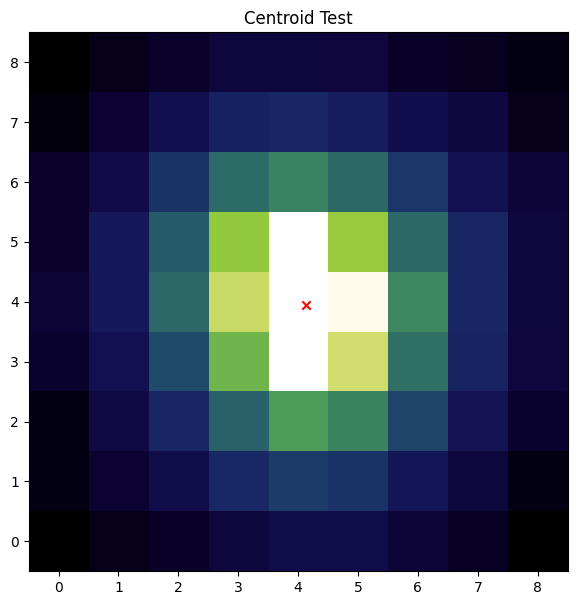

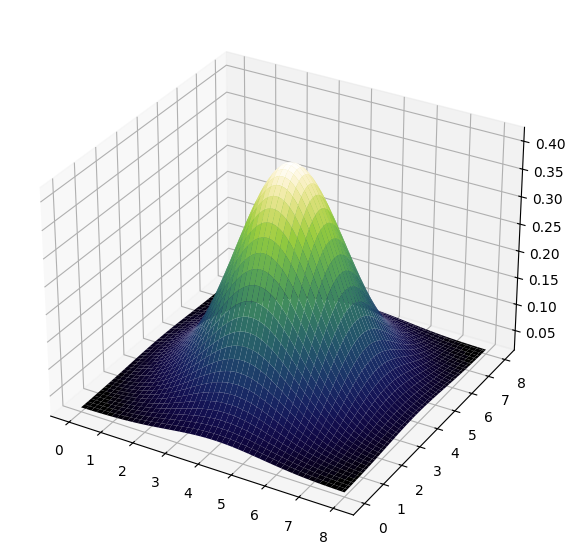

In [10]:
from scipy.optimize import curve_fit

# Your 2D Gaussian function
def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
    x, y = xy
    g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
    return g.ravel()

star = science_imgs[0][50:59,52:61]

# Create coordinate matrices and flatten them for fitting
xx, yy = np.meshgrid(np.arange(star.shape[1]), np.arange(star.shape[0])) 
xx_flat = xx.ravel()
yy_flat = yy.ravel()

# Use centroid equation for initial guess
x = np.sum(xx * star) / np.sum(star) 
y = np.sum(yy * star) / np.sum(star) 

# Fit Gaussian
initial_guess = (1,x,y,1,1,0)
popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), star.ravel(), p0=initial_guess)

# get centroid coordinates
centroid_x, centroid_y = popt[1], popt[2]

# Plotting
plt.figure(figsize=(7,7))
vmin,vmax = ZScaleInterval().get_limits(star)
plt.scatter(centroid_x, centroid_y, marker='x', color='red')
plt.imshow(star, vmin=vmin, vmax=vmax, cmap='cma:lacerta', origin='lower')
plt.title('Centroid Test');

from mpl_toolkits.mplot3d import Axes3D
# Create a grid of points
x = np.linspace(np.min(xx_flat), np.max(xx_flat), 100)
y = np.linspace(np.min(yy_flat), np.max(yy_flat), 100)
x, y = np.meshgrid(x, y)

# Compute the 2D Gaussian
z = gauss((x, y), *popt)

# Create a 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z.reshape(x.shape), cmap='cma:lacerta')

plt.show()


Now to apply this to all the stars